# 2. Diagnose seeds 0 and 2

**Scientific question.** Did the previously fragmented runs split after forming one connected school, or were their groups disconnected from the start? When do splits occur, how long do they persist, and do components reconnect?

**Why this is needed.** A final 10 + 10 or 19 + 1 state does not reveal its history. A random initial configuration may be disconnected, so calling every fragmented record a newly formed split would be misleading.

**Hypotheses.** Disconnection may precede first cohesion, emerge after an observed cohesive period, or disappear through reconnection. Event histories distinguish these possibilities; spatial snapshots locate them without proving a causal mechanism.

**What changes:** only observer diagnostics. **What remains controlled:** the shared 2D baseline, speed 1 BL/s, `dt=0.125 s`, a 20 × 20 BL reflecting arena, all social rules and a 5.5-BL social range. Seeds **0 and 2** are compared with **seed 1**, which ended connected in the earlier checks. Runs are generated here, so this notebook does not depend on executing notebook 01.

Local-range motivation follows [Couzin et al. (2002)](https://doi.org/10.1006/jtbi.2002.3065); order parameters follow [Tunstrøm et al. (2013)](https://doi.org/10.1371/journal.pcbi.1002915). The event threshold below is our diagnostic convention. No light or parameter tuning is introduced.

Use the **mesa-env** kernel and **Restart Kernel → Run All**.


In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_one"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from types import SimpleNamespace
from IPython.display import Markdown, display
from shiner_model import GoldenShinersModel, compute_group_metrics
from handlings.trial_one.diagnostics import (
    graph_components, run_case, fragmentation_episodes, summarize_case,
)

OUTPUT_DIR = MODEL_DIR / "handlings" / "trial_one"
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR = OUTPUT_DIR / "data"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
SOCIAL_RANGE = 5.5
PERSISTENCE_S = 2.5
DURATION_S = 62.5
COLORS = {0: "tab:red", 2: "tab:orange", 1: "tab:blue"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)


## Define an episode before reading the results

An episode is a sequence of fragmented **post-update** records (`NumberOfGroups > 1`). It is persistent when their accumulated duration is **at least 2.5 seconds**, equivalent to 20 baseline updates. This is a diagnostic threshold, not a biological constant.

Each post-update sample represents its preceding `dt` interval; `t=0` receives no interval weight. Thus `Duration_s = fragmented interval count × dt`. The exact continuous onset is only bracketed between the previous sample and the first observed fragmented sample. These durations are discrete estimates.

- **Initial disconnection:** already fragmented at `t=0`. Its onset is left-censored and it is not counted as a split from a connected school.
- **Observed split:** one connected sample is followed by a fragmented episode (`FromConnected=True`).
- **Reconnection:** a fragmented episode is followed by one connected component.
- **Right censoring:** the run ends while fragmented. The observed duration is a lower bound, not proof of permanent separation.

The number or membership of components may change within a fragmented episode without the whole group ever reconnecting.


In [2]:
seed_models, seed_frames, seed_agents = {}, {}, {}
episode_tables, summary_rows = [], []
for seed in (0, 2, 1):
    model, frame, agents = run_case(seed=seed, duration=DURATION_S)
    seed_models[seed], seed_frames[seed], seed_agents[seed] = model, frame, agents
    episodes = fragmentation_episodes(frame, min_duration_s=PERSISTENCE_S).copy()
    episodes.insert(0, "Seed", seed)
    episodes["Origin"] = np.where(
        episodes["FromConnected"].astype(bool), "Split after connected state", "Initial disconnected state"
    )
    episodes["OnsetLowerBound_s"] = [
        float(frame.loc[int(start) - 1, "Time"]) if bool(from_connected) else np.nan
        for start, from_connected in zip(episodes["StartStep"], episodes["FromConnected"])
    ]
    for _, episode in episodes.iterrows():
        start, end = int(episode["StartStep"]), int(episode["EndStep"])
        assert frame.loc[start:end, "NumberOfGroups"].gt(1).all()
        np.testing.assert_allclose(episode["Duration_s"], (end - start + 1) * model.dt)
        assert bool(episode["Persistent"]) == (episode["Duration_s"] >= PERSISTENCE_S - 1e-12)
        if episode["FromConnected"]:
            assert frame.loc[start - 1, "NumberOfGroups"] == 1
        else:
            assert start == 1 and frame.iloc[0]["NumberOfGroups"] > 1
        if episode["RightCensored"]:
            assert end == model.steps and not episode["Reconnected"]
        else:
            assert frame.loc[end + 1, "NumberOfGroups"] == 1 and episode["Reconnected"]
    episode_tables.append(episodes)
    summary_rows.append({
        "Seed": seed,
        "InitialGroups": int(frame["NumberOfGroups"].iloc[0]),
        "InitialComponentSizes": frame["ComponentSizes"].iloc[0],
        "TotalFragmentedEpisodes": len(episodes),
        "PersistentInitialEpisodes": int((~episodes["FromConnected"].astype(bool) & episodes["Persistent"].astype(bool)).sum()),
        "ReconnectedEpisodes": int(episodes["Reconnected"].sum()),
        **summarize_case(frame, persistence_s=PERSISTENCE_S),
    })
all_episodes = pd.concat(episode_tables, ignore_index=True)
seed_summary = pd.DataFrame(summary_rows)
all_episodes.to_csv(DATA_DIR / "02_seed_fragmentation_episodes.csv", index=False)
seed_summary.to_csv(DATA_DIR / "02_seed_summary.csv", index=False)
display(seed_summary[[
    "Seed", "InitialComponentSizes", "FirstConnectedTime_s", "FinalComponentSizes",
    "TotalFragmentedEpisodes", "PersistentInitialEpisodes", "PersistentSplitEvents",
    "ReconnectedEpisodes", "ConnectedTimeFraction",
]])
all_episodes[[
    "Seed", "Origin", "StartStep", "EndStep", "OnsetLowerBound_s", "StartTime", "EndTime",
    "Duration_s", "Persistent", "SizesAtStart", "Reconnected", "RightCensored",
]]


,Seed,InitialComponentSizes,FirstConnectedTime_s,FinalComponentSizes,TotalFragmentedEpisodes,PersistentInitialEpisodes,PersistentSplitEvents,ReconnectedEpisodes,ConnectedTimeFraction
0,0,18+2,NaN,10+10,1,1,0,0,0.0
1,2,19+1,NaN,19+1,1,1,0,0,0.0
2,1,20,0.0,20,0,0,0,0,1.0


,Seed,Origin,StartStep,EndStep,OnsetLowerBound_s,StartTime,EndTime,Duration_s,Persistent,SizesAtStart,Reconnected,RightCensored
0,0,Initial disconnected state,1,500,NaN,0.125,62.5,62.5,True,18+2,False,True
1,2,Initial disconnected state,1,500,NaN,0.125,62.5,62.5,True,19+1,False,True


## First persistent split after an observed connected state

The next table isolates `1 component → 2 or more components` transitions satisfying the duration threshold. If there is no such event, it is reported explicitly. Initial disconnection is never assigned a false split time.

The centroid, component sizes, polarization, rotation and spacing below refer to the **first observed fragmented sample**. Reconnection occurs one update after the episode's last fragmented sample. All shorter episodes remain in the previous table.


In [3]:
event_rows, selected_steps = [], {}
for seed in (0, 2, 1):
    frame = seed_frames[seed]
    episodes = all_episodes.loc[all_episodes["Seed"].eq(seed)]
    splits = episodes.loc[episodes["FromConnected"].astype(bool) & episodes["Persistent"].astype(bool)]
    if len(splits):
        event = splits.iloc[0]
        step = int(event["StartStep"])
        state = frame.loc[step]
        selected_steps[seed] = (step, "First persistent split")
        event_rows.append({
            "Seed": seed, "Event": "First persistent split", "Step": step,
            "OnsetLowerBound_s": event["OnsetLowerBound_s"], "FirstObserved_s": event["StartTime"],
            "ObservedDuration_s": event["Duration_s"],
            "ReconnectionTime_s": float(frame.loc[int(event["EndStep"]) + 1, "Time"]) if event["Reconnected"] else np.nan,
            "RightCensored": bool(event["RightCensored"]), "ComponentSizes": state["ComponentSizes"],
            **{name: state[name] for name in ("CentroidX", "CentroidY", "Polarization", "Rotation", "MeanNND", "MeanDistanceToCentroid")},
        })
    else:
        connected = frame.index[frame["NumberOfGroups"].eq(1)]
        step = int(connected[0]) if len(connected) and connected[0] > 0 else 250
        selected_steps[seed] = (step, "First cohesion" if len(connected) and connected[0] > 0 else "Mid-run comparison")
        event_rows.append({"Seed": seed, "Event": "No persistent split after an observed connected state"})
first_events = pd.DataFrame(event_rows)
first_events.to_csv(DATA_DIR / "02_first_persistent_splits.csv", index=False)
first_events


,Seed,Event
0,0,No persistent split after an observed connected state
1,2,No persistent split after an observed connected state
2,1,No persistent split after an observed connected state


## Initial, event and final positions

Colours identify components **within each panel**, not tracked subgroup identities across panels. Black crosses show whole-group centroids; coloured stars show component centroids. The whole-group centroid can lie in empty space between disconnected subgroups.

The middle panel uses the first persistent split after an observed cohesive state when available. Otherwise its title states the alternative comparison state. All positions and headings come from the saved individual records.


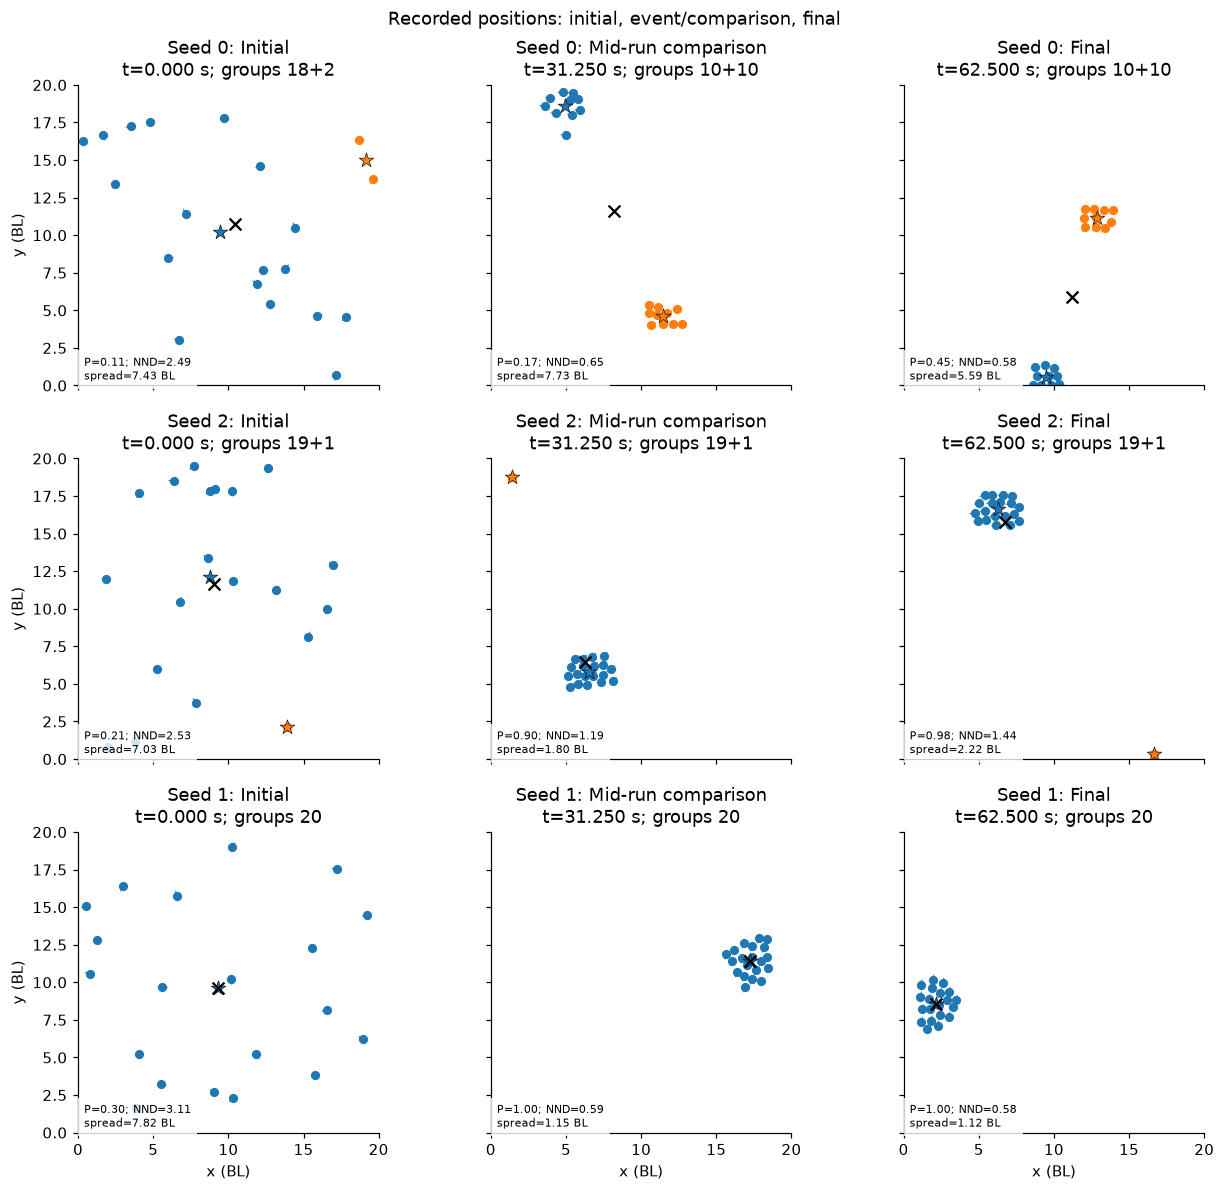

,Seed,Stage,Step,Time_s,Group,Size,GroupCentroidX,GroupCentroidY
0,0,Initial,0,0.00,1,18,9.473924,10.240799
1,0,Initial,0,0.00,2,2,19.159078,15.013955
2,0,Mid-run comparison,250,31.25,1,10,4.943494,18.600679
3,0,Mid-run comparison,250,31.25,2,10,11.428199,4.625712
4,0,Final,500,62.50,1,10,9.476745,0.583424
5,0,Final,500,62.50,2,10,12.875931,11.165549
6,2,Initial,0,0.00,1,19,8.808334,12.113770
7,2,Initial,0,0.00,2,1,13.875177,2.144146
8,2,Mid-run comparison,250,31.25,1,19,6.528664,5.821380
9,2,Mid-run comparison,250,31.25,2,1,1.377651,18.773402


In [4]:
def snapshot(seed, step):
    state = seed_agents[seed].xs(step, level="Step").sort_index()
    positions = state[["X", "Y"]].to_numpy()
    headings = state[["DirX", "DirY"]].to_numpy()
    return positions, headings, graph_components(positions, SOCIAL_RANGE)


fig, axes = plt.subplots(3, 3, figsize=(12, 11), sharex=True, sharey=True)
component_rows = []
for row, seed in enumerate((0, 2, 1)):
    middle_step, middle_label = selected_steps[seed]
    for axis, (step, label) in zip(axes[row], [(0, "Initial"), (middle_step, middle_label), (500, "Final")]):
        positions, headings, components = snapshot(seed, step)
        for group_number, indices in enumerate(components):
            points = positions[indices]
            centroid = points.mean(axis=0)
            color = plt.get_cmap("tab10")(group_number % 10)
            axis.scatter(points[:, 0], points[:, 1], s=25, color=color)
            axis.quiver(points[:, 0], points[:, 1], headings[indices, 0], headings[indices, 1],
                        color=color, angles="xy", scale_units="xy", scale=2.5, width=0.004)
            axis.scatter(*centroid, marker="*", s=100, color=color, edgecolor="black", linewidth=0.4)
            component_rows.append({
                "Seed": seed, "Stage": label, "Step": step, "Time_s": step * 0.125,
                "Group": group_number + 1, "Size": len(indices),
                "GroupCentroidX": centroid[0], "GroupCentroidY": centroid[1],
            })
        axis.scatter(*positions.mean(axis=0), marker="x", color="black", s=60)
        record = seed_frames[seed].loc[step]
        axis.set(title=f"Seed {seed}: {label}\nt={record['Time']:.3f} s; groups {record['ComponentSizes']}",
                 xlim=(0, 20), ylim=(0, 20), aspect="equal")
        axis.text(0.02, 0.02,
                  f"P={record['Polarization']:.2f}; NND={record['MeanNND']:.2f}\nspread={record['MeanDistanceToCentroid']:.2f} BL",
                  transform=axis.transAxes, fontsize=7,
                  bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})
    axes[row, 0].set_ylabel("y (BL)")
for axis in axes[-1]:axis.set_xlabel("x (BL)")
fig.suptitle("Recorded positions: initial, event/comparison, final", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_seed_position_snapshots.png", dpi=180, bbox_inches="tight")
plt.show()
component_snapshots = pd.DataFrame(component_rows)
component_snapshots.to_csv(DATA_DIR / "02_snapshot_component_centroids.csv", index=False)
component_snapshots


## Time histories and persistent episode windows

Shading marks persistent fragmented episodes. Its left edge is the sample preceding `StartTime`, matching interval weighting; an initially disconnected run starts at the observation boundary of 0 seconds. Short unshaded episodes remain visible in the connectivity curves.

Polarization, nearest-neighbour spacing and global spread are shown together because locally compact subgroups may have a large whole-population spread.


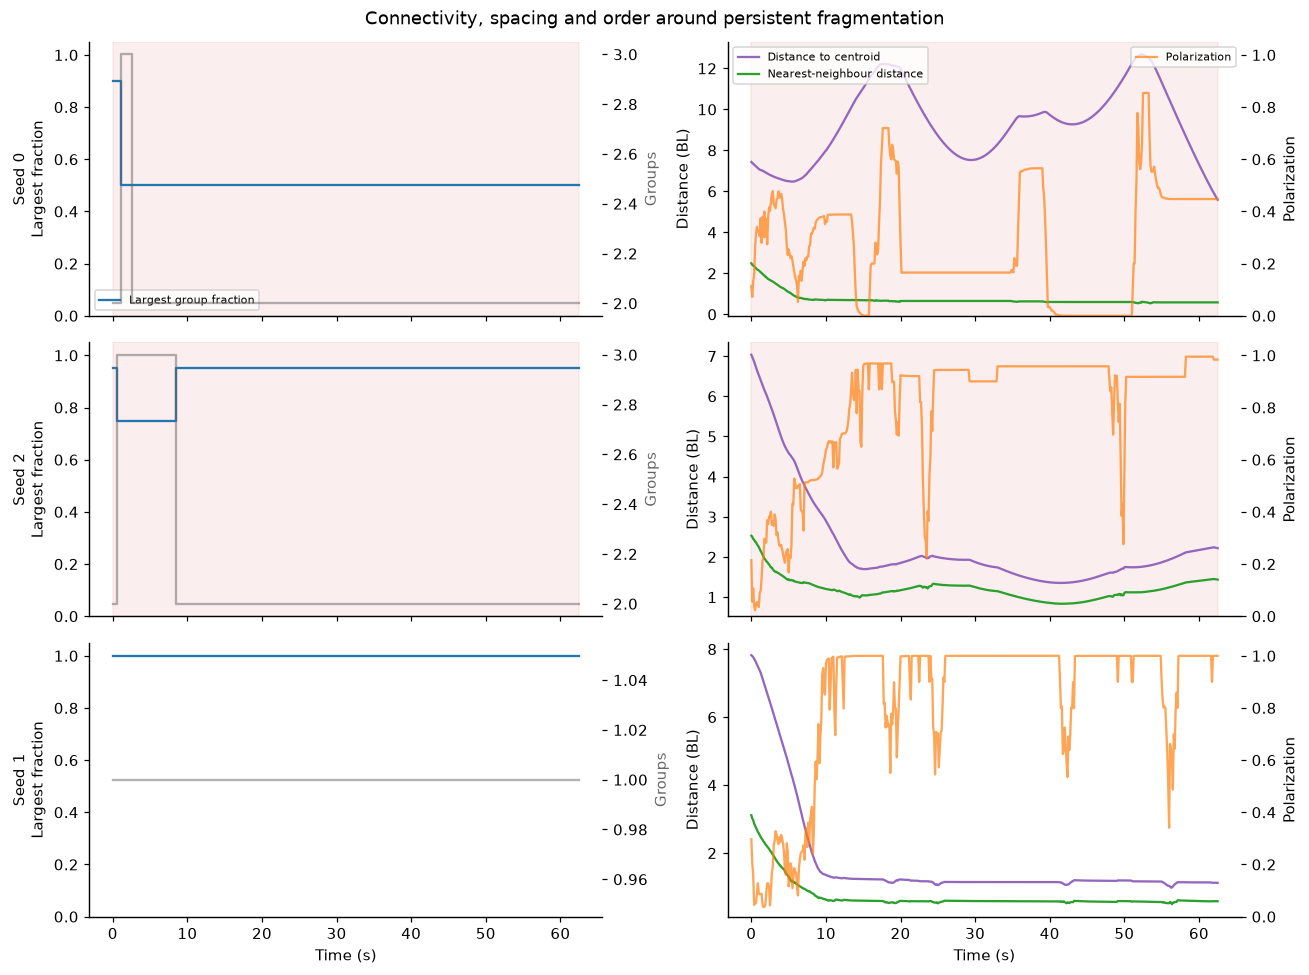

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for row, seed in enumerate((0, 2, 1)):
    frame = seed_frames[seed]
    left, right = axes[row]
    left.step(frame["Time"], frame["LargestGroupFraction"], where="post", color="tab:blue", label="Largest group fraction")
    left.set(ylabel=f"Seed {seed}\nLargest fraction", ylim=(0, 1.05))
    group_axis = left.twinx()
    group_axis.step(frame["Time"], frame["NumberOfGroups"], where="post", color="0.4", alpha=0.5)
    group_axis.set_ylabel("Groups", color="0.4")
    right.plot(frame["Time"], frame["MeanDistanceToCentroid"], color="tab:purple", label="Distance to centroid")
    right.plot(frame["Time"], frame["MeanNND"], color="tab:green", label="Nearest-neighbour distance")
    right.set_ylabel("Distance (BL)")
    order_axis = right.twinx()
    order_axis.plot(frame["Time"], frame["Polarization"], color="tab:orange", alpha=0.7, label="Polarization")
    order_axis.set(ylabel="Polarization", ylim=(0, 1.05))
    persistent = all_episodes.loc[all_episodes["Seed"].eq(seed) & all_episodes["Persistent"].astype(bool)]
    for _, episode in persistent.iterrows():
        start = max(0, float(episode["StartTime"]) - 0.125)
        for axis in (left, right):axis.axvspan(start, episode["EndTime"], color="tab:red", alpha=0.08)
    if row == 0:
        left.legend(loc="lower left", fontsize=7)
        right.legend(loc="upper left", fontsize=7)
        order_axis.legend(loc="upper right", fontsize=7)
for axis in axes[-1]:axis.set_xlabel("Time (s)")
fig.suptitle("Connectivity, spacing and order around persistent fragmentation")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_connectivity_and_spacing_time_series.png", dpi=180, bbox_inches="tight")
plt.show()


## Whole-group centroid paths

Colour shows time. Red crosses mark first observed samples of persistent splits from connected states. A central whole-group centroid does not guarantee that every fish or subgroup is far from the walls.

These trajectories localize events; temporal coincidence with a wall is not a causal wall-effect test. Individual wall distances and reflected fish are examined in notebook 03.


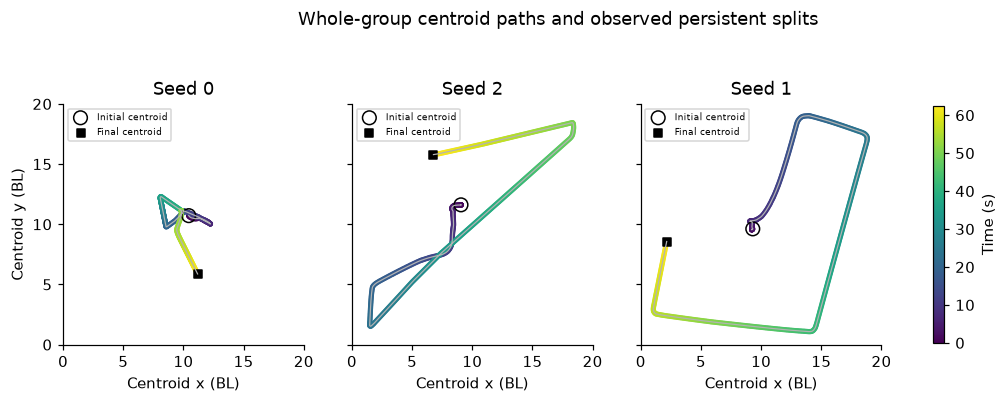

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for axis, seed in zip(axes, (0, 2, 1)):
    frame = seed_frames[seed]
    axis.plot(frame["CentroidX"], frame["CentroidY"], color="0.7", linewidth=0.8)
    points = axis.scatter(frame["CentroidX"], frame["CentroidY"], c=frame["Time"], cmap="viridis", s=6)
    axis.scatter(frame["CentroidX"].iloc[0], frame["CentroidY"].iloc[0], marker="o", facecolors="none", edgecolors="black", s=80, label="Initial centroid")
    axis.scatter(frame["CentroidX"].iloc[-1], frame["CentroidY"].iloc[-1], marker="s", color="black", s=30, label="Final centroid")
    splits = all_episodes.loc[
        all_episodes["Seed"].eq(seed) & all_episodes["FromConnected"].astype(bool) & all_episodes["Persistent"].astype(bool)
    ]
    if len(splits):
        onset = frame.loc[splits["StartStep"].astype(int)]
        axis.scatter(onset["CentroidX"], onset["CentroidY"], marker="x", color="red", s=60, label="Persistent split observed")
    axis.set(title=f"Seed {seed}", xlabel="Centroid x (BL)", xlim=(0, 20), ylim=(0, 20), aspect="equal")
    axis.legend(fontsize=6, loc="upper left")
axes[0].set_ylabel("Centroid y (BL)")
fig.colorbar(points, ax=axes, label="Time (s)", shrink=0.7)
fig.suptitle("Whole-group centroid paths and observed persistent splits")
fig.savefig(FIGURE_DIR / "02_centroid_paths.png", dpi=180, bbox_inches="tight")
plt.show()


## Interpretation of the actual histories

The next output separates initial disconnection, persistent post-cohesion splits, reconnections and censoring using the executed event table. Its onset bracket acknowledges the finite observation timestep.


In [7]:
interpretations = []
for seed in (0, 2, 1):
    row = seed_summary.loc[seed_summary["Seed"].eq(seed)].iloc[0]
    splits = all_episodes.loc[
        all_episodes["Seed"].eq(seed) & all_episodes["FromConnected"].astype(bool) & all_episodes["Persistent"].astype(bool)
    ]
    initial = f"initial sizes {row['InitialComponentSizes']}"
    cohesion = "never fully connected during this run" if pd.isna(row["FirstConnectedTime_s"]) else f"first connected at {row['FirstConnectedTime_s']:.3f} s"
    if len(splits):
        event = splits.iloc[0]
        ending = "right-censored at the end" if event["RightCensored"] else f"reconnected at {event['EndTime'] + 0.125:.3f} s"
        text = (
            f"{len(splits)} persistent split(s) after a connected state; the first is observed at step {int(event['StartStep'])} "
            f"({event['StartTime']:.3f} s), onset in ({event['OnsetLowerBound_s']:.3f}, {event['StartTime']:.3f}] s, "
            f"lasting {event['Duration_s']:.3f} diagnostic seconds ({ending})"
        )
    else:
        text = "no persistent split after an observed connected state"
    interpretations.append(f"- **Seed {seed}:** {initial}; {cohesion}; {text}. Final sizes: **{row['FinalComponentSizes']}**.")
display(Markdown("\n".join(interpretations)))
print("Saved event histories, first-event details, component centroids and seed summaries in data/.")


- **Seed 0:** initial sizes 18+2; never fully connected during this run; no persistent split after an observed connected state. Final sizes: **10+10**.
- **Seed 2:** initial sizes 19+1; never fully connected during this run; no persistent split after an observed connected state. Final sizes: **19+1**.
- **Seed 1:** initial sizes 20; first connected at 0.000 s; no persistent split after an observed connected state. Final sizes: **20**.

Saved event histories, first-event details, component centroids and seed summaries in data/.


## What this establishes and what remains unresolved

The tables identify which losses of connectivity follow an observed cohesive state, which intervals are inherited from initial disconnection, and which episodes reconnect. Initial disconnection is left-censored, while final disconnection is right-censored; neither proves indefinite permanence.

The event histories do not isolate a cause. Finite local range, walls, numerical resolution and simplified social assumptions remain competing possibilities. Later notebooks compare these with matched seeds and controlled changes rather than adjusting parameters until every trajectory looks attractive.

Saved evidence: `data/02_seed_summary.csv`, `02_seed_fragmentation_episodes.csv`, `02_first_persistent_splits.csv`, `02_snapshot_component_centroids.csv` and three figures. The shared core model and its default parameters are unchanged.


### Actual result for the three diagnosed seeds

| Seed | Initial component sizes | First whole-group cohesion | Persistent split after cohesion | Final sizes |
|---|---|---|---|---|
| 0 | 18 + 2 | Not observed | None | 10 + 10 |
| 2 | 19 + 1 | Not observed | None | 19 + 1 |
| 1 | 20 | 0.000 s | None | 20 |

Seeds 0 and 2 each have one initially disconnected episode lasting the entire **62.5 seconds of weighted post-update observation**, with no whole-group reconnection. The first post-update sample is step 1 at 0.125 s, but disconnection is already present at step 0. Their onset is therefore left-censored; both are also right-censored at the end. There is **no exact 1 → multiple whole-group split timestep to report** for these runs. Assigning one would invent an event that the records do not contain.

The main conclusion is **failure of whole-group assembly over the observed period**, not breakup after a previously cohesive 20-fish state. Seed 0's 18 + 2 → 10 + 10 reorganization still requires care: a whole-population episode can contain subgroup fission or merging. Component colours are not longitudinal identity labels, so these plots do not claim that the same initial subgroups remained unchanged.

The spatial states show compact final subgroups and a whole-group centroid between them. This makes local spacing insufficient as a cohesion criterion. The event histories alone do not distinguish finite-range separation from wall or timestep effects; the matched interventions in notebooks 03–05 are needed for that causal comparison.
